# Nivel 4: Base + Extras + Cuestionario frente al nivel 2

¿Cuánto mejora la predicción si el usuario trae Extras y además responde el cuestionario?

| Modelo | Variables | Papel |
|---|---|---|
| Cox del nivel 2 | Base + Extras (29) | Listón a superar |
| Cox del nivel 3 | Base + Cuestionario (23) | Referencia |
| Cox | Base + Extras + Cuestionario (33) | Candidato |

Los dos bloques ya se podaron en su nivel, así que aquí no compiten algoritmos ni se quitan variables por falta de efecto: Cox ganó en los niveles 1, 2 y 3, con XGBoost optimizado lejos del listón en los tres.

Listones fijados antes de ver los resultados:

- **Hábitos con signo contrario al conocido:** salen, como en el nivel 3. Lo que solo pierda fuerza se queda: cada bloque tiene que funcionar igual con el otro o sin él.
- **Quedarse con el nivel 4:** el intervalo del bootstrap frente al Cox del nivel 2 no incluye el 0. Si lo incluye, no hay modelo del nivel 4 y la app usa el del nivel 2 aunque el usuario responda el cuestionario.

Sin pesos muestrales. Todo con validación cruzada dentro de train: **el test no se toca**.

Notebook de trabajo: importa de `src/`. Tiempo aproximado, si se ejecuta entero: **unos 25 minutos**, casi todo en el bootstrap.

In [1]:
# Imports
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.config.model_sets import BASE, EXTRAS, QUESTIONNAIRE
from src.config.paths import GOLD_TABLE
from src.models.s1_split import split_data
from src.models.s5_evaluation import compare_risks, evaluate_level, plot_calibration
from src.utils.notebook_helpers import cox_weights

C:\Data\1_MisCosas\Evolve\TFM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos

Mismo reparto que en los niveles anteriores: 80/20 con 5 bloques dentro de train.

In [2]:
LEVEL_2 = BASE + EXTRAS
LEVEL_3 = BASE + QUESTIONNAIRE
LEVEL_4 = BASE + EXTRAS + QUESTIONNAIRE

gold = pd.read_parquet(GOLD_TABLE)
train, test, folds = split_data(gold)

          people       deaths      
part        test train   test train
cycle                              
1999_2000    829  3316    212   846
2001_2002    925  3697    188   750
2003_2004    877  3511    165   661
2005_2006    874  3497    120   479
2007_2008   1043  4170    136   544
2009_2010   1120  4479     99   396
2011_2012    993  3968     70   278
2013_2014   1061  4248     51   206
2015_2016   1011  4043     31   122
2017_2018    966  3867     14    57
train: 38796 people, 4339 deaths
test:  9699 people, 1086 deaths
folds: [7760, 7759, 7759, 7759, 7759] people in each validation part


## 2. Signos esperados

Los del nivel 3, para los hábitos que quedaron. `above`: suma riesgo (hazard ratio por encima de 1); `below`: lo resta. Un hábito tiene **signo contrario** si alguna de sus columnas tiene un efecto claro (intervalo del 95 % que no incluye el 1) en el sentido opuesto al esperado.

In [3]:
# Expected direction of each questionnaire column: above = adds risk, below = lowers it
EXPECTED_SIGNS = {
    "smoking_former":             "above",
    "smoking_current":            "above",
    "physical_activity_moderate": "below",
    "physical_activity_intense":  "below",
    "sedentary_hours":            "above",
    "sleep_hours_squared":        "above",
}

## 3. Entrenar y evaluar

Cox simple con los tres juegos de variables y los mismos bloques. Cada persona se evalúa con un modelo entrenado sin ella.

| Columna | Qué mide | Mejor |
|---|---|---|
| `c_index` | De dos personas, cuántas veces da más riesgo a la que muere antes en 10 años | Alto |
| `c_index_std` | Cuánto varía entre los 5 bloques | Bajo |
| `c_index_fit` | Lo mismo con personas ya vistas; muy por encima de `c_index` = sobreajuste | Cerca de `c_index` |
| `c_index_same_age` | Lo mismo, dentro de cada grupo de edad: **lo que más importa para el producto** | Alto |
| `c_index_female`, `c_index_male` | Lo mismo, por sexo | Altos y parecidos |
| `calibration_gap` | Diferencia media entre el riesgo previsto y el observado | Bajo |
| `worst_underestimate` | Grupo donde más se queda corto el riesgo previsto; es el error peor | Bajo |
| `seconds_per_fit` | Tiempo de un entrenamiento | Bajo |

In [4]:
levels = {"level_2": LEVEL_2, "level_3": LEVEL_3, "level_4": LEVEL_4}
results = {name: evaluate_level(columns, train, folds, models=["cox"]) for name, columns in levels.items()}

summary = pd.concat({name: level_summary.iloc[0] for name, (level_summary, _) in results.items()}, axis=1).T
summary.insert(0, "variables", [len(columns) for columns in levels.values()])
summary

,variables,c_index,c_index_std,c_index_fit,c_index_same_age,c_index_female,c_index_male,calibration_gap,worst_underestimate,seconds_per_fit
level_2,29,0.8587,0.0050,0.8595,0.7310,0.8635,0.8507,0.0049,0.0182,5.8105
level_3,23,0.8554,0.0058,0.8560,0.7249,0.8617,0.8464,0.0055,0.0187,5.1975
level_4,33,0.8637,0.0053,0.8646,0.7444,0.8707,0.8545,0.0062,0.0236,6.1675


## 4. Por grupo de edad

¿Mejora en todos los grupos? Los grupos con pocas muertes son menos fiables.

In [5]:
by_age = pd.DataFrame({name: details["cox"]["by_age"]["c_index"] for name, (_, details) in results.items()})
by_age["deaths"] = results["level_2"][1]["cox"]["by_age"]["deaths"].astype(int)
by_age.round(3)

,level_2,level_3,level_4,deaths
18-29,0.714,0.686,0.714,81
30-39,0.718,0.720,0.726,89
40-49,0.749,0.745,0.769,217
50-59,0.764,0.759,0.777,388
60-69,0.747,0.745,0.762,828
70-79,0.709,0.701,0.722,1246


## 5. Calibración

Sobre la diagonal, el riesgo previsto coincide con el observado; por encima de ella, el modelo se queda corto. En los niveles 2 y 3 subió la infraestimación del grupo de mayor riesgo.

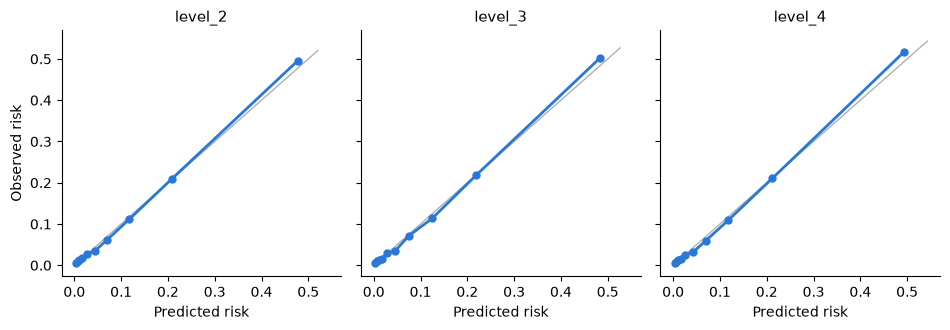

In [6]:
plot_calibration({name: details["cox"] for name, (_, details) in results.items()});

In [7]:
pd.DataFrame({name: details["cox"]["calibration"]["gap"] for name, (_, details) in results.items()}).round(3)

,level_2,level_3,level_4
0,0.000,0.002,0.001
1,0.002,0.003,0.003
2,0.003,0.003,0.003
3,0.000,-0.001,0.001
4,0.001,0.001,0.000
5,-0.009,-0.011,-0.011
6,-0.008,-0.004,-0.010
7,-0.006,-0.011,-0.009
8,0.001,-0.001,-0.001
9,0.018,0.019,0.024


## 6. Peso de cada variable y signos

Cox simple ajustado con todo train, sin validación: describe el modelo, no mide su acierto.

- **`hazard_ratio`:** por cuánto se multiplica el riesgo al subir la variable una desviación estándar (o al dar esa respuesta frente a la de referencia), a igualdad de las demás.
- **`low`, `high`:** su intervalo de confianza del 95 %. Si incluye el 1, el efecto no se distingue de cero (`clear` = False).
- **`variable`:** la pregunta o variable de la que sale cada columna.
- **`expected`, `contrary`:** signo esperado y si el efecto es claro en el sentido opuesto, solo en el cuestionario.

In [8]:
weights = cox_weights(LEVEL_4, train, EXPECTED_SIGNS)
weights.sort_values("p").round(3)

,hazard_ratio,low,high,p,clear,variable,expected,contrary
covariate,,,,,,,,
age,3.276,3.099,3.463,0.000,True,age,NaN,False
smoking_current,1.834,1.682,1.999,0.000,True,smoking,above,False
urine_acr,1.152,1.124,1.180,0.000,True,urine_acr,NaN,False
rdw,1.204,1.166,1.243,0.000,True,rdw,NaN,False
alt,0.743,0.701,0.787,0.000,True,alt,NaN,False
albumin,0.845,0.816,0.876,0.000,True,albumin,NaN,False
ggt,1.173,1.132,1.215,0.000,True,ggt,NaN,False
erythrocytes,0.766,0.722,0.813,0.000,True,erythrocytes,NaN,False
sex_male,1.422,1.310,1.543,0.000,True,sex,NaN,False


Cambio de cada peso frente al nivel en que entró su variable (nivel 2 para Base y Extras, nivel 3 para el cuestionario). Si un efecto deja de ser claro al juntar los bloques, aparece aquí.

In [9]:
earlier_weights = pd.concat([cox_weights(LEVEL_2, train, EXPECTED_SIGNS), cox_weights(LEVEL_3, train, EXPECTED_SIGNS).loc[lambda table: table["variable"].isin(QUESTIONNAIRE)]])
weight_changes = pd.DataFrame({
    "earlier": earlier_weights["hazard_ratio"],
    "level_4": weights["hazard_ratio"],
    "earlier_clear": earlier_weights["clear"],
    "level_4_clear": weights["clear"],
})
weight_changes[weight_changes["earlier_clear"] != weight_changes["level_4_clear"]].round(3)

,earlier,level_4,earlier_clear,level_4_clear
covariate,,,,


In [10]:
contrary = [variable for variable in QUESTIONNAIRE if weights.loc[weights["variable"] == variable, "contrary"].any()]
print("Habits against the expected sign:", contrary)
weights[weights["variable"].isin(QUESTIONNAIRE)].round(3)

Habits against the expected sign: []


,hazard_ratio,low,high,p,clear,variable,expected,contrary
covariate,,,,,,,,
sedentary_hours,1.089,1.048,1.130,0.000,True,sedentary_hours,above,False
sleep_hours,1.013,0.981,1.047,0.432,False,sleep_hours,NaN,False
smoking_former,1.271,1.181,1.367,0.000,True,smoking,above,False
smoking_current,1.834,1.682,1.999,0.000,True,smoking,above,False
physical_activity_moderate,0.826,0.769,0.888,0.000,True,physical_activity,below,False
physical_activity_intense,0.738,0.668,0.816,0.000,True,physical_activity,below,False
sleep_hours_squared,1.036,1.020,1.051,0.000,True,sleep_hours,above,False


## 7. Modelo final

Sin los hábitos con signo contrario, si los hay. Si salen, se vuelve a evaluar y se comprueba que no aparecen signos contrarios nuevos.

In [11]:
FINAL = [variable for variable in LEVEL_4 if variable not in contrary]

if contrary:
    results["final"] = evaluate_level(FINAL, train, folds, models=["cox"])
    final_weights = cox_weights(FINAL, train, EXPECTED_SIGNS)
    print("Contrary signs left:", final_weights.index[final_weights["contrary"]].tolist())
    display(pd.concat([summary, results["final"][0].rename(index={"cox": "final"})]))
else:
    results["final"] = results["level_4"]
    print("No habit against the expected sign: the final model is level_4")

print("Variables:", len(FINAL))

No habit against the expected sign: the final model is level_4
Variables: 33


## 8. ¿Supera al nivel 2?

Comparación con bootstrap del modelo final frente al Cox del nivel 2, de unos 22 minutos. La mejora es real si el intervalo (`low`, `high`) no incluye el 0.

In [12]:
versus_level_2 = compare_risks(results["final"][1]["cox"]["risk"], results["level_2"][1]["cox"]["risk"], train)
versus_level_2

,difference,low,high
c_index,0.0050,0.0037,0.0062
c_index_same_age,0.0133,0.0090,0.0166


## 9. Conclusión

**Modelo del nivel 4: Cox simple con 33 variables**: las 19 de Base, los 10 Extras del nivel 2 y los 4 hábitos del nivel 3. Supera al nivel 2, así que la app lo usa cuando el usuario trae Extras y responde el cuestionario. Las cifras son de validación cruzada dentro de train; el test sigue sin tocar.

### Qué se hizo y por qué

**1. Comparar Cox con los tres juegos de variables**

| Cox simple | Variables | C-index | Misma edad | En entrenamiento | Mayor infraestimación |
|---|---|---|---|---|---|
| Nivel 2 (Base + Extras) | 29 | 0,859 | 0,731 | 0,860 | 1,8 puntos |
| Nivel 3 (Base + Cuestionario) | 23 | 0,855 | 0,725 | 0,856 | 1,9 puntos |
| Nivel 4 (todo) | 33 | 0,864 | 0,744 | 0,865 | 2,4 puntos |

Las mejoras no se suman: los hábitos aportan +0,021 sobre Base, pero sobre el nivel 2 solo +0,013, porque los Extras ya recogen parte de lo mismo. Aun así, mejora en todos los grupos de edad salvo el de 18-29, que se queda igual, y no sobreajusta.

**2. Revisar los signos al juntar los bloques**

Ningún hábito pasa a tener signo contrario y ninguna variable cambia entre efecto claro y no claro respecto a su nivel. No sale nada.

**3. Confirmar que supera al nivel 2**

Nivel 4 frente al nivel 2, con bootstrap: **+0,005** de C-index global (intervalo del 95 %: 0,004 a 0,006) y **+0,013** en misma edad (0,009 a 0,017). El intervalo no incluye el 0: la mejora es real, algo más de 1 pareja más de cada 100 entre personas de edad parecida.

### Resultado final

| Cox simple, 33 variables | |
|---|---|
| C-index | 0,864 |
| C-index misma edad | 0,744 |
| Diferencia media de calibración | 0,6 puntos |
| Mayor infraestimación | 2,4 puntos |

**Peso de los hábitos**, a igualdad de lo demás: fumar sube el riesgo un 83 % y haber fumado, un 27 %, frente a no haber fumado nunca; la actividad moderada lo baja un 17 % y la intensa, un 26 %, frente a ser sedentario. Más horas sentado y dormir lejos de lo habitual lo suben. Con los Extras, el tabaco y la actividad pesan algo menos que en el nivel 3.

### Limitaciones

- **La infraestimación del grupo de mayor riesgo sigue subiendo** con cada bloque: 1,4 puntos en Base, 1,8 en el nivel 2 y 2,4 aquí. Es el error peor; corregir la calibración al traducir el riesgo a edad pasa a ser necesario, no opcional.
- **Sin competición de algoritmos:** se usa Cox directamente porque ganó en los tres niveles anteriores. XGBoost podría quedarse menos corto en el grupo de mayor riesgo, como en los niveles 2 y 3.
- **Es el mejor caso:** en NHANES casi todos tienen los Extras y responden el cuestionario; el usuario real traerá menos datos.
- **Sin pesos muestrales** y con población de EE. UU.; se asume equivalencia con España.
- **Falta el test,** que se mira una sola vez, al final.